In [ ]:
! pip install pennylane
! pip install basis-set-exchange
! pip install openfermion openfermionpyscf
! pip install pyscf

  Using cached scipy-1.15.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached scipy-1.15.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.6 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.13.0
    Uninstalling scipy-1.13.0:
      Successfully uninstalled scipy-1.13.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.2 which is incompatible.


In [ ]:
# Import library
import pennylane as qml              # Pustaka simulasi
from pennylane import qchem
from pennylane import numpy as np    # Pustaka numerik
import matplotlib.pyplot as plt      # Pustaka grafik
import pandas as pd                  # Pustaka tabel
import basis_set_exchange as bse     # Pustaka basis set

# Unduh basis set sto-6g
sto6g_basis = bse.get_basis('sto-6g', fmt='nwchem')
with open("sto-6g.gbs", "w") as file:
    file.write(sto6g_basis)

In [ ]:
# Definisikan sistem atom hidrogen
symbols = ["H"]  # Atom hidrogen
geometry = np.array([[0.0, 0.0, 0.0]])  # Koordinat atom hidrogen

# Basis set dan informasi tambahan
charge = 0  # Atom netral
multiplicity = 2  # Satu elektron -> spin 1/2
basis_set = "sto-6g"

# Membuat Hamiltonian
H, qubits =  qml.qchem.molecular_hamiltonian(
    symbols=symbols,
    coordinates=geometry,
    charge=charge,
    mult=multiplicity,
    basis=basis_set,
    method = "openfermion"
)

# Params
# params_H = np.random.uniform(0, 2 * np.pi, (1, qubits, 3))

# Params
# Params
params_H = np.random.uniform(0, 2 * np.pi, (9, qubits, 1))

# Circuit Anstaz:
def ansatz(params, wires):
  for i in range(9):
    qml.RY(params[i][0][0], wires = 0)
    qml.RY(params[i][1][0], wires = 1)
    qml.CNOT(wires = [0, 1])
    qml.CNOT(wires = [1, 0])

# Extract terms from the Hamiltonian
coefficients = H.coeffs  # Ambil koefisien dari hamiltonian
operators    = H.ops     # Ambil operator hamiltonian
data = []
for coef, op in zip(coefficients, operators):
    data.append([coef, str(op)])
columns = ["Coefficient", "Operator"]
df = pd.DataFrame(data, columns=columns)

print("jumlah qubit =", qubits)
print("wires =", H.wires)
print()
print('HAMILTONIAN')
print(df)
print()
print('Params')
print(params_H)

jumlah qubit = 2
wires = Wires([0, 1])

HAMILTONIAN
   Coefficient     Operator
0    -0.277289          I()
1     0.041770         Z(0)
2     0.041770         Z(1)
3     0.193750  Z(0) @ Z(1)

Params
[[[2.25011798]
  [0.90790913]]

 [[2.27397708]
  [5.58162442]]

 [[2.35389981]
  [4.292959  ]]

 [[0.38664972]
  [3.1294339 ]]

 [[3.77995062]
  [2.61529221]]

 [[2.7193036 ]
  [0.473512  ]]

 [[5.4614414 ]
  [1.22284224]]

 [[0.89725684]
  [4.34335495]]

 [[4.46303094]
  [1.99619852]]]


/usr/local/lib/python3.11/dist-packages/pennylane/ops/op_math/sum.py:541: PennyLaneDeprecationWarning: Sum.coeffs is deprecated and will be removed in future releases. You can access both (coeffs, ops) via op.terms(). Also consider op.operands.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pennylane/ops/op_math/sum.py:557: PennyLaneDeprecationWarning: Sum.ops is deprecated and will be removed in future releases. You can access both (coeffs, ops) via op.terms(). Also consider op.operands.
  warnings.warn(


MATRIKS HAMILTONIAN
[[ 1.00000e-06  0.00000e+00  0.00000e+00  0.00000e+00]
 [ 0.00000e+00 -4.71039e-01  0.00000e+00  0.00000e+00]
 [ 0.00000e+00  0.00000e+00 -4.71039e-01  0.00000e+00]
 [ 0.00000e+00  0.00000e+00  0.00000e+00 -1.67079e-01]]

Classical diagonalization ke-0: -0.471039 Eh
Classical diagonalization ke-1: -0.471039 Eh
Classical diagonalization ke-2: -0.16707899999999995 Eh
Classical diagonalization ke-3: 1.000000000001e-06 Eh


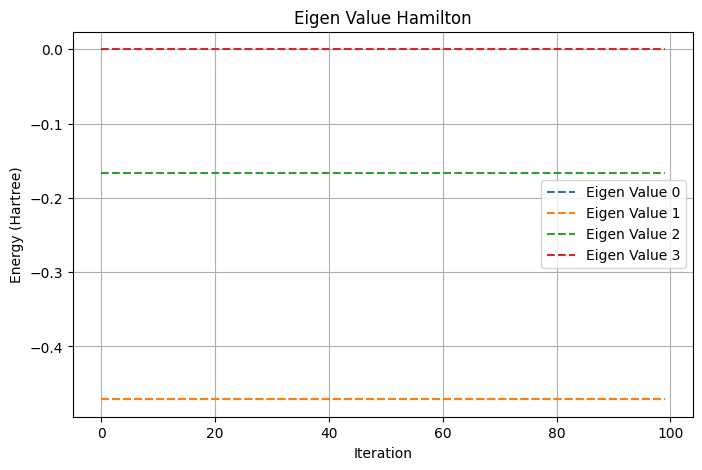

In [ ]:
I_gate = np.array([ # Identitas
    [1, 0],
    [0, 1]])

# Gerbang Pauli X, Y & Z
X_gate = np.array([
    [0, 1],
    [1, 0]])

Y_gate = np.array([
    [0, -1j],
    [1j, 0]])

Z_gate = np.array([
    [1, 0],
    [0, -1]])

c0  = -0.277289
c1  =  0.041770
c2  =  0.041770
c3  =  0.193750

Eigen_value_Hamiltonian = (
    c0 * np.kron(I_gate, I_gate) + # I()
    c1 * np.kron(Z_gate, I_gate) + # Z(0)
    c2 * np.kron(I_gate, Z_gate) +
    c3 * np.kron(Z_gate, Z_gate)
)
eigen_data = []
print('MATRIKS HAMILTONIAN')
print(Eigen_value_Hamiltonian)
print()
# Menghitung energi elektronik menggunakan eigenvalue
for i in range(4):
  electronic_energy = np.linalg.eigvalsh(Eigen_value_Hamiltonian)[i]  # Ambil nilai eigen terendah
  eigen_data.append(electronic_energy)
  # Cetak hasil perhitungan
  print(f"Classical diagonalization ke-{i}: {electronic_energy} Eh")

# Graph plot:
Iterations = [*range(0, 100)]
plt.figure(figsize=(8, 5))
plt.title('Eigen Value Hamilton')

for i in range(4):
  y = np.full(100, eigen_data[i])
  plt.plot(Iterations, y, linestyle = '--', label = f'Eigen Value {i}')

plt.legend()
plt.xlabel('Iteration')
plt.ylabel('Energy (Hartree)')
plt.grid()
plt.show()

In [ ]:
def WEIGHTED_SSVQE(hamiltonian, ansatz, params, opt_name='Adam', stepsize=1, iterations=500, k=0, device_name='default.qubit'):
    """Calculates the kth excited state energy for of a given Hamiltonian.

    Args:
        => hamiltonian (qml.Hamiltonian): Hamiltonian for which the Kth excited state energy is to be found.
        => ansatz (function(params, wires, *args)): The circuit ansatz for which the cost function will be optimized.
           ansatz must have atleast two arguments 'params' and 'wires'.
           There is no need to prepare orthogonal basis stats, they will be prepared by the algorithm.
        => params (any): Parameters that can be passed to the provided ansatz.
        => opt_name(string): Name of the optimizer to use for optimization.
           Currently the function supports 'Adam' 'Adagrad' 'GradientDescent'.
        => stepsize (float): Stepsize for the optimizer.
        => iterations (int): No. of Iterations for the optimization.
        => k (int): K for which the Kth excited state energy will be calculated. K <= 2^qubits-1.
        => device_name(string): device name for creating device such that qml.device(device_name, wires=wires).
    Returns:
        => (Energy, Energies): The function returns a tuple of Energy of Kth excited state and list of energies at each iteration for plotting the graph.
    """

    # Calculate number of qubits required for the given Hamiltonian and create the device.
    qubits = len(hamiltonian.wires)
    device = qml.device(device_name, wires=qubits)
    wires  = range(qubits)

    #Define the weights for the cost function.
    weights = 0.23493884933161424
    print(f'Bobot= {weights}')

    # State Preparation for orthogonal states.
    def state_prep(state_value):
      for index, value in enumerate(np.binary_repr(state_value, qubits)):
        if value == '1':
          qml.PauliX(index)

    @qml.qnode(device)
    def circuit(state_value):
      state_prep(state_value)
      return qml.state()

    @qml.qnode(device)
    def unitary(params, state_value):
      state_prep(state_value)
      ansatz(params, wires)
      return qml.state()

    # Cost of each orthogonal state.
    @qml.qnode(device)
    def state_cost(params, state_value):
      state_prep(state_value)
      ansatz(params, wires)
      return qml.expval(hamiltonian)

    # Total cost of the system.
    def total_cost(params):
      cost = 0
      for index in range(k+1):
        if index == k:
          print(f'Energi state ke-{index}: {state_cost(params, state_value=index)} Ha')
          cost += weights * state_cost(params, state_value=index)
        else:
          print(f'Energi state ke-{index}: {state_cost(params, state_value=index)} Ha')
          cost += state_cost(params, state_value=index)
      return cost

    @qml.qnode(device)
    def circuit_visualization(params, state_value):
      ansatz(params, wires=range(qubits))
      return [qml.expval(qml.PauliZ(i)) for i in range(qubits)]

    # Optimizers options.
    optimizers = {
        'Adam': qml.AdamOptimizer(stepsize=stepsize),
        'Adagrad': qml.AdagradOptimizer(stepsize=stepsize),
        'GradientDescent': qml.GradientDescentOptimizer(stepsize=stepsize)
    }

    # Define the Optimizer and initial parameters.
    optimizer = optimizers[opt_name]
    energies  = []
    Error     = []
    state     = circuit(state_value = k)
    print(f'State yang diperhitungkan: {state}')
    print()

    # Optimization loop.
    for i in range(iterations):
      print(f'iterasi ke-{i}')
      fungsi_biaya = total_cost(params)
      print(f'Fungsi Biaya ke-{i} adalah sebesar: {fungsi_biaya}')
      energy = state_cost(params, state_value=k)
      print(f'Energi Ground state ke-{i} adalah: {energy}')
      error = (np.abs(energy - eigen_data[k]) / eigen_data[k]) * 100
      print(f'Errornya sebesar: {error} %')
      Error.append(error)
      params = optimizer.step(total_cost, params)
      print('Params')
      print(params)
      quantum_state = unitary(params, state_value = k)
      print('Kuantum State Terparameterisasi')
      print(quantum_state)
      # Visualize the circuit
      print('Circuit')
      print(qml.draw(circuit_visualization, level = 'device')(params, state_value = k))
      print()
      energies.append(energy)
    return energies[-1], energies, Error

Streaming output truncated to the last 5000 lines.
  6.11625775e-03+0.j]
Circuit
0: ──RY(1.87)─╭●─╭X──RY(2.32)─╭●─╭X──RY(2.20)─╭●─╭X──RY(0.55)─╭●─╭X──RY(3.92)─╭●─╭X──RY(2.78)─╭●─╭X
1: ──RY(0.62)─╰X─╰●──RY(5.71)─╰X─╰●──RY(4.15)─╰X─╰●──RY(3.32)─╰X─╰●──RY(2.89)─╰X─╰●──RY(0.34)─╰X─╰●

───RY(5.62)─╭●─╭X──RY(1.00)─╭●─╭X──RY(4.61)─╭●─╭X─┤  <Z>
───RY(1.12)─╰X─╰●──RY(4.52)─╰X─╰●──RY(1.85)─╰X─╰●─┤  <Z>

iterasi ke-84
Energi state ke-0: -0.47102757710457754 Ha
Fungsi Biaya ke-84 adalah sebesar: -0.11066267696840765
Energi Ground state ke-84 adalah: -0.47102757710457754
Errornya sebesar: -0.002425042389789714 %
Energi state ke-0: Autograd ArrayBox with value -0.47102757710457754 Ha
Params
[[[1.87425921]
  [0.61874449]]

 [[2.31831483]
  [5.70725779]]

 [[2.20178229]
  [4.14536756]]

 [[0.55312716]
  [3.32292568]]

 [[3.91836249]
  [2.89172928]]

 [[2.78495007]
  [0.33960539]]

 [[5.62149662]
  [1.12338348]]

 [[0.99849864]
  [4.51775499]]

 [[4.60551504]
  [1.85043689]]]
Kuantum State Terparameter

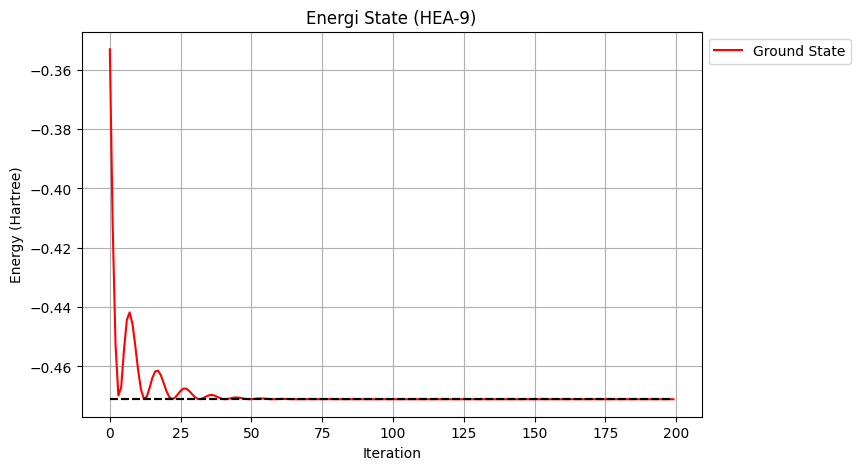

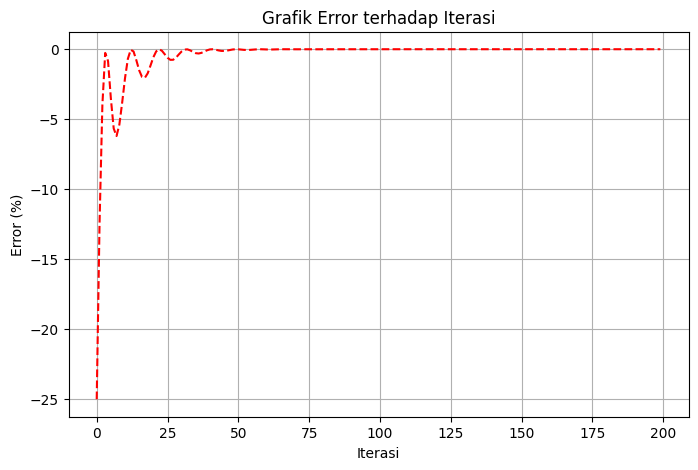

In [ ]:
energy_G_0, energies_G_0, errors = WEIGHTED_SSVQE(H, ansatz, params_H, stepsize = 0.05, iterations=200, k=0, opt_name = 'Adam')

# Output
print('Weighted SSVQE:')
print('energi =', energies_G_0)
print(f'Energy of Ground state for the H2 hamiltonian is: {energy_G_0} Ha')
print(f'Error: {errors[-1]} %')

# Graph plot:
Iterations = [*range(0, 200)]
plt.figure(figsize=(8, 5))
plt.style.use('default')
plt.title('Energi State (HEA-9)')
plt.plot(Iterations, energies_G_0, linestyle = '-', label = 'Ground State', color = 'red')
for i in range(2):
  y = np.full(200, eigen_data[i])
  plt.plot(Iterations, y, linestyle = '--', color = 'black')
plt.xlabel('Iteration')
plt.ylabel('Energy (Hartree)')
plt.legend(loc='upper left', bbox_to_anchor = (1, 1))
plt.grid(True)
plt.show()
print()

plt.figure(figsize=(8, 5))
plt.style.use('default')
plt.plot(range(len(errors)), errors, linestyle='--', color='red')
plt.title('Grafik Error terhadap Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Error (%)')
plt.grid(True)
plt.show()

Streaming output truncated to the last 5000 lines.
Energi state ke-2: -0.4589158950669254 Ha
Energi state ke-3: -3.2616201391388877e-06 Ha
Fungsi Biaya ke-98 adalah sebesar: -1.109155200097462
Energi Ground state ke-98 adalah: -3.2616201391388877e-06
Errornya sebesar: 426.16201391356253 %
Energi state ke-0: Autograd ArrayBox with value -0.4610645186168111 Ha
Energi state ke-1: Autograd ArrayBox with value -0.18917402013244305 Ha
Energi state ke-2: Autograd ArrayBox with value -0.4589158950669254 Ha
Energi state ke-3: Autograd ArrayBox with value -3.2616201391388877e-06 Ha
Params
[[[2.54469966]
  [0.59558707]]

 [[2.46839527]
  [5.59268683]]

 [[2.75487889]
  [4.04765522]]

 [[0.59798851]
  [3.22994206]]

 [[3.85094991]
  [2.42766916]]

 [[2.48600983]
  [0.17519835]]

 [[5.88458403]
  [1.46178478]]

 [[1.1233237 ]
  [4.62281697]]

 [[4.90775095]
  [2.26108684]]]
Kuantum State Terparameterisasi
[-9.99994553e-01+0.j  1.02198688e-03+0.j -7.17415514e-04+0.j
 -3.05521605e-03+0.j]
Circuit
0: 

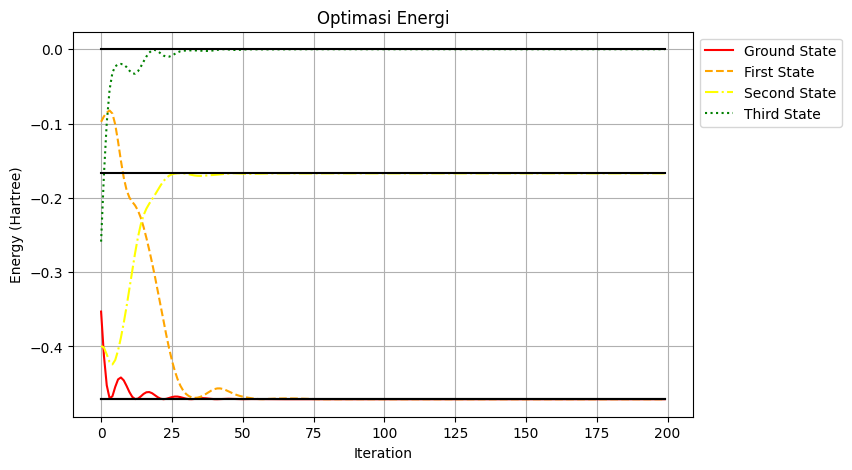

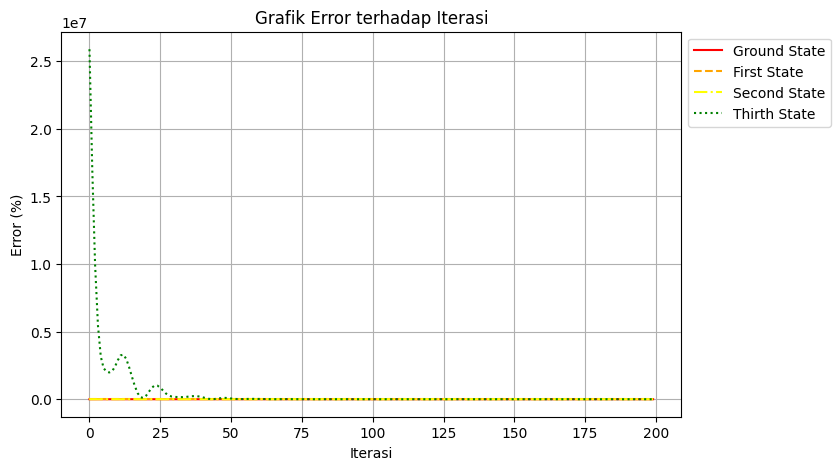

In [ ]:
energy_G_0, energies_G_0, error0= WEIGHTED_SSVQE(H, ansatz, params_H, stepsize = 0.05, iterations=200, k=0, opt_name = 'Adam')
energy_G_1, energies_G_1, error1= WEIGHTED_SSVQE(H, ansatz, params_H, stepsize = 0.05, iterations=200, k=1, opt_name = 'Adam')
energy_G_2, energies_G_2, error2= WEIGHTED_SSVQE(H, ansatz, params_H, stepsize = 0.05, iterations=200, k=2, opt_name = 'Adam')
energy_G_3, energies_G_3, error3= WEIGHTED_SSVQE(H, ansatz, params_H, stepsize = 0.05, iterations=200, k=3, opt_name = 'Adam')

# Output
print('Weighted SSVQE:')
print(f'Energy of Ground state for the H2 hamiltonian is: {energy_G_0} Ha')
print(f'Energy of First state for the H2 hamiltonian is: {energy_G_1} Ha')
print(f'Energy of Second state for the H2 hamiltonian is: {energy_G_2} Ha')
print(f'Energy of Thirth state for the H2 hamiltonian is: {energy_G_3} Ha')
print()

# Graph plot:
Iterations = [*range(0, 200)]
plt.figure(figsize=(8, 5))
plt.title('Optimasi Energi')
# Plot Energi
plt.plot(Iterations, energies_G_0, linestyle = '-', label = 'Ground State', color = 'red')
plt.plot(Iterations, energies_G_1, linestyle = '--', label = 'First State', color = 'orange')
plt.plot(Iterations, energies_G_2, linestyle = '-.', label = 'Second State', color = 'yellow')
plt.plot(Iterations, energies_G_3, linestyle = ':', label = 'Third State', color = 'green')
# Plot Eigen Value
for i in range(4):
  y = np.full(200, eigen_data[i])
  plt.plot(Iterations, y, linestyle = '-', color = 'black')
plt.xlabel('Iteration')
plt.ylabel('Energy (Hartree)')
plt.legend(loc='upper left', bbox_to_anchor = (1, 1))
plt.grid(True)
plt.show()
print()

plt.figure(figsize=(8, 5))
plt.style.use('default')
plt.plot(range(len(error0)), error0, linestyle='-', color='red', label = 'Ground State')
plt.plot(range(len(error1)), error1, linestyle='--', color='orange', label = 'First State')
plt.plot(range(len(error2)), error2, linestyle='-.', color='yellow', label = 'Second State')
plt.plot(range(len(error3)), error3, linestyle=':', color='green', label = 'Thirth State')
plt.title('Grafik Error terhadap Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Error (%)')
plt.grid(True)
plt.legend(loc='upper left', bbox_to_anchor = (1, 1))
plt.show()